In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans , AgglomerativeClustering
from sklearn.metrics import (silhouette_score,davies_bouldin_score,calinski_harabasz_score)
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import dendrogram , linkage
sns.set_theme(style='darkgrid')
plt.rcParams['figure.figsize'] = (12,8)
import warnings
warnings.filterwarnings('ignore')

In [2]:
import pandas as pd
from pathlib import Path
file_path = '/content/Wholesale customers data - Wholesale customers data.csv'
candidates = [
    Path(file_path),
    Path.cwd() / "Wholesale customers data - Wholesale customers data.csv",
    Path.cwd() / "Wholesale customers data.csv",
]

csv_path = next((path for path in candidates if path.is_file()), None)
if csv_path is None:
    raise FileNotFoundError(
        "CSV not found. Place it in the notebook folder or update file_path to its location."
    )

df = pd.read_csv(csv_path)
df.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


In [3]:
df.tail()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
435,1,3,29703,12051,16027,13135,182,2204
436,1,3,39228,1431,764,4510,93,2346
437,2,3,14531,15488,30243,437,14841,1867
438,1,3,10290,1981,2232,1038,168,2125
439,1,3,2787,1698,2510,65,477,52


In [4]:
df.shape

(440, 8)

In [5]:
df.describe()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000
mean,1.322727,2.543182,12000.297727,5796.265909,7951.277273,3071.931818,2881.493182,1524.870455
std,0.468052,0.774272,12647.328865,7380.377175,9503.162829,4854.673333,4767.854448,2820.105937
min,1.000000,1.000000,3.000000,55.000000,3.000000,25.000000,3.000000,3.000000
25%,1.000000,2.000000,3127.750000,1533.000000,2153.000000,742.250000,256.750000,408.250000
50%,1.000000,3.000000,8504.000000,3627.000000,4755.500000,1526.000000,816.500000,965.500000
75%,2.000000,3.000000,16933.750000,7190.250000,10655.750000,3554.250000,3922.000000,1820.250000
max,2.000000,3.000000,112151.000000,73498.000000,92780.000000,60869.000000,40827.000000,47943.000000


In [6]:
df.dtypes

Channel             int64
Region              int64
Fresh               int64
Milk                int64
Grocery             int64
Frozen              int64
Detergents_Paper    int64
Delicassen          int64
dtype: object

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           440 non-null    int64
 1   Region            440 non-null    int64
 2   Fresh             440 non-null    int64
 3   Milk              440 non-null    int64
 4   Grocery           440 non-null    int64
 5   Frozen            440 non-null    int64
 6   Detergents_Paper  440 non-null    int64
 7   Delicassen        440 non-null    int64
dtypes: int64(8)
memory usage: 27.6 KB


In [8]:
df.isnull().sum()

Channel             0
Region              0
Fresh               0
Milk                0
Grocery             0
Frozen              0
Detergents_Paper    0
Delicassen          0
dtype: int64

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
features = ["Fresh", "Milk", "Grocery", "Frozen", "Detergents_Paper", "Delicassen"]
X = df[features]
print("Number of records used for clustering:", len(X))
X.head()

Number of records used for clustering: 440


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,12669,9656,7561,214,2674,1338
1,7057,9810,9568,1762,3293,1776
2,6353,8808,7684,2405,3516,7844
3,13265,1196,4221,6404,507,1788
4,22615,5410,7198,3915,1777,5185


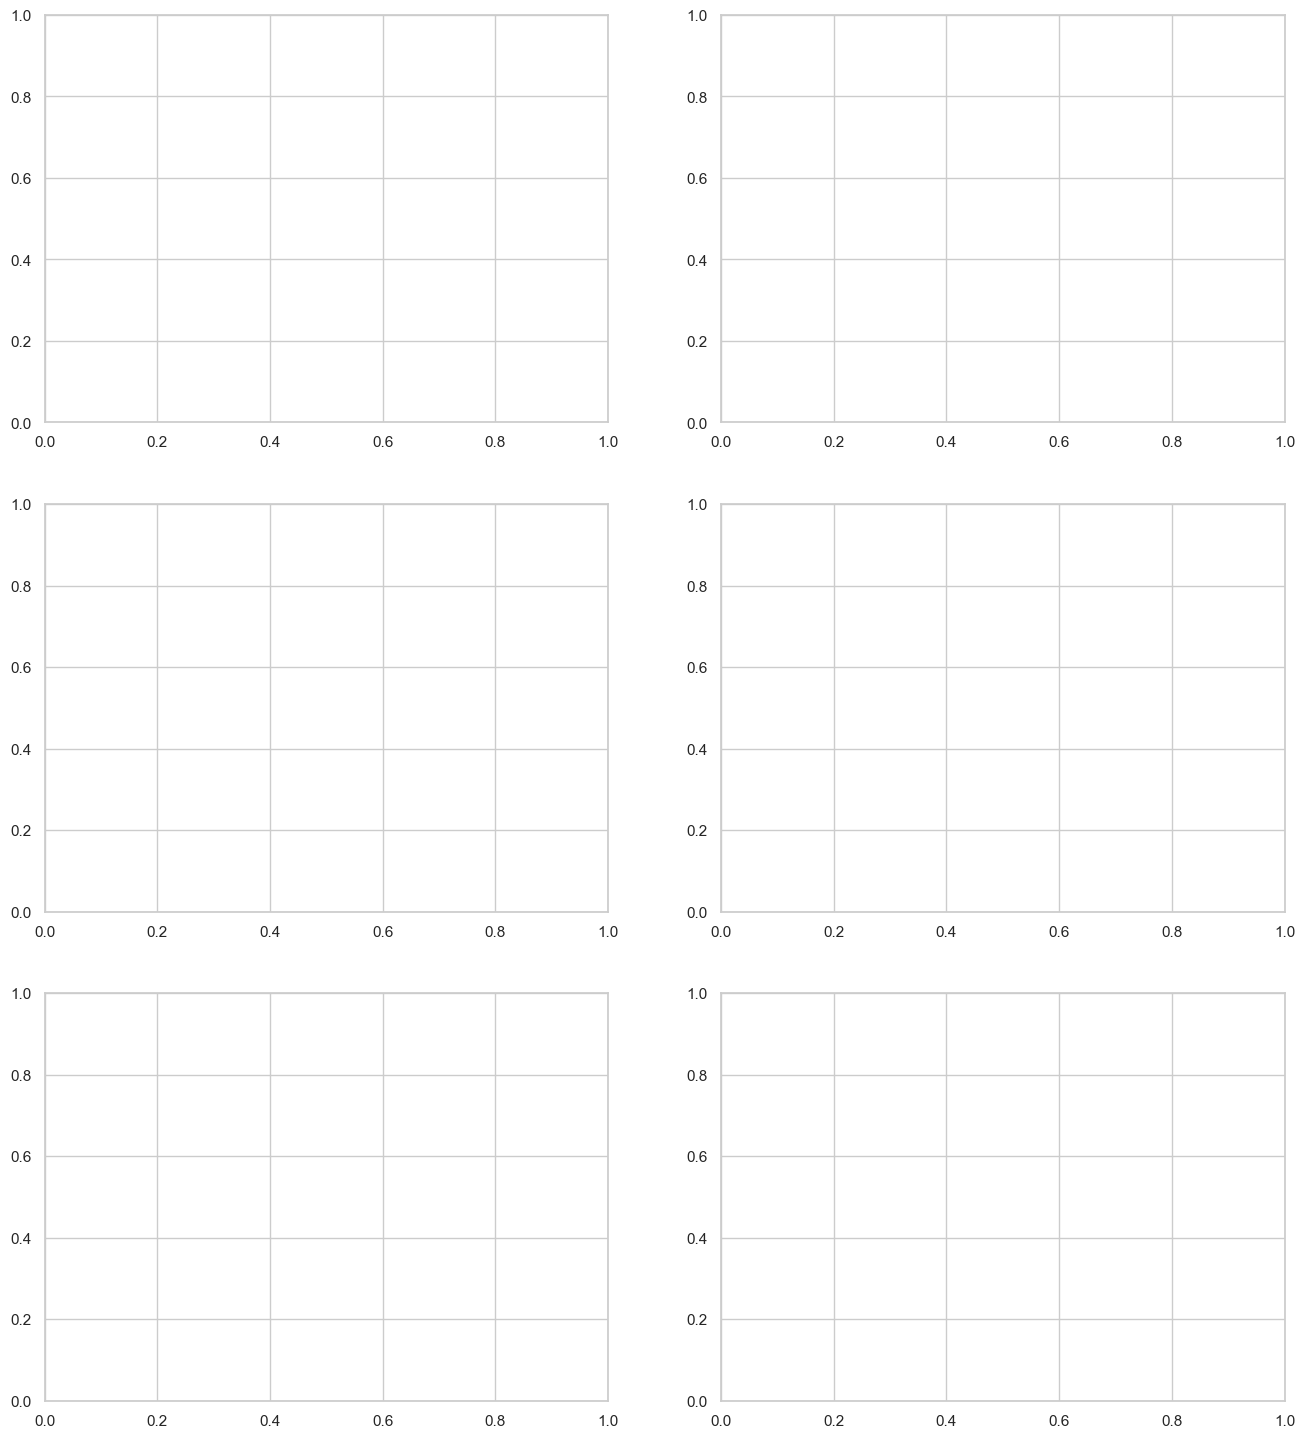

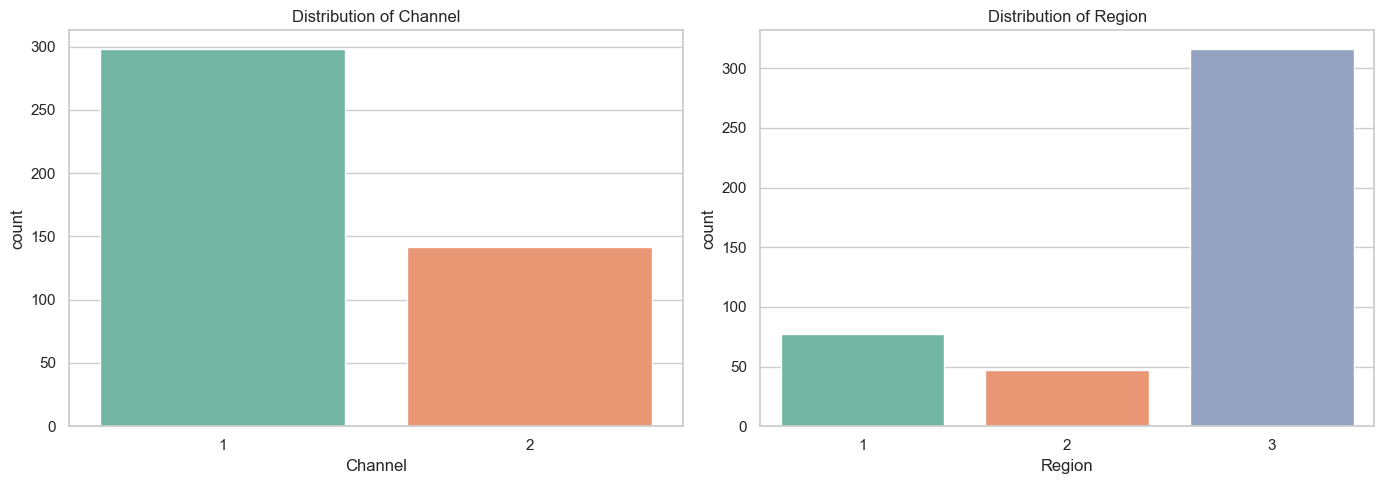

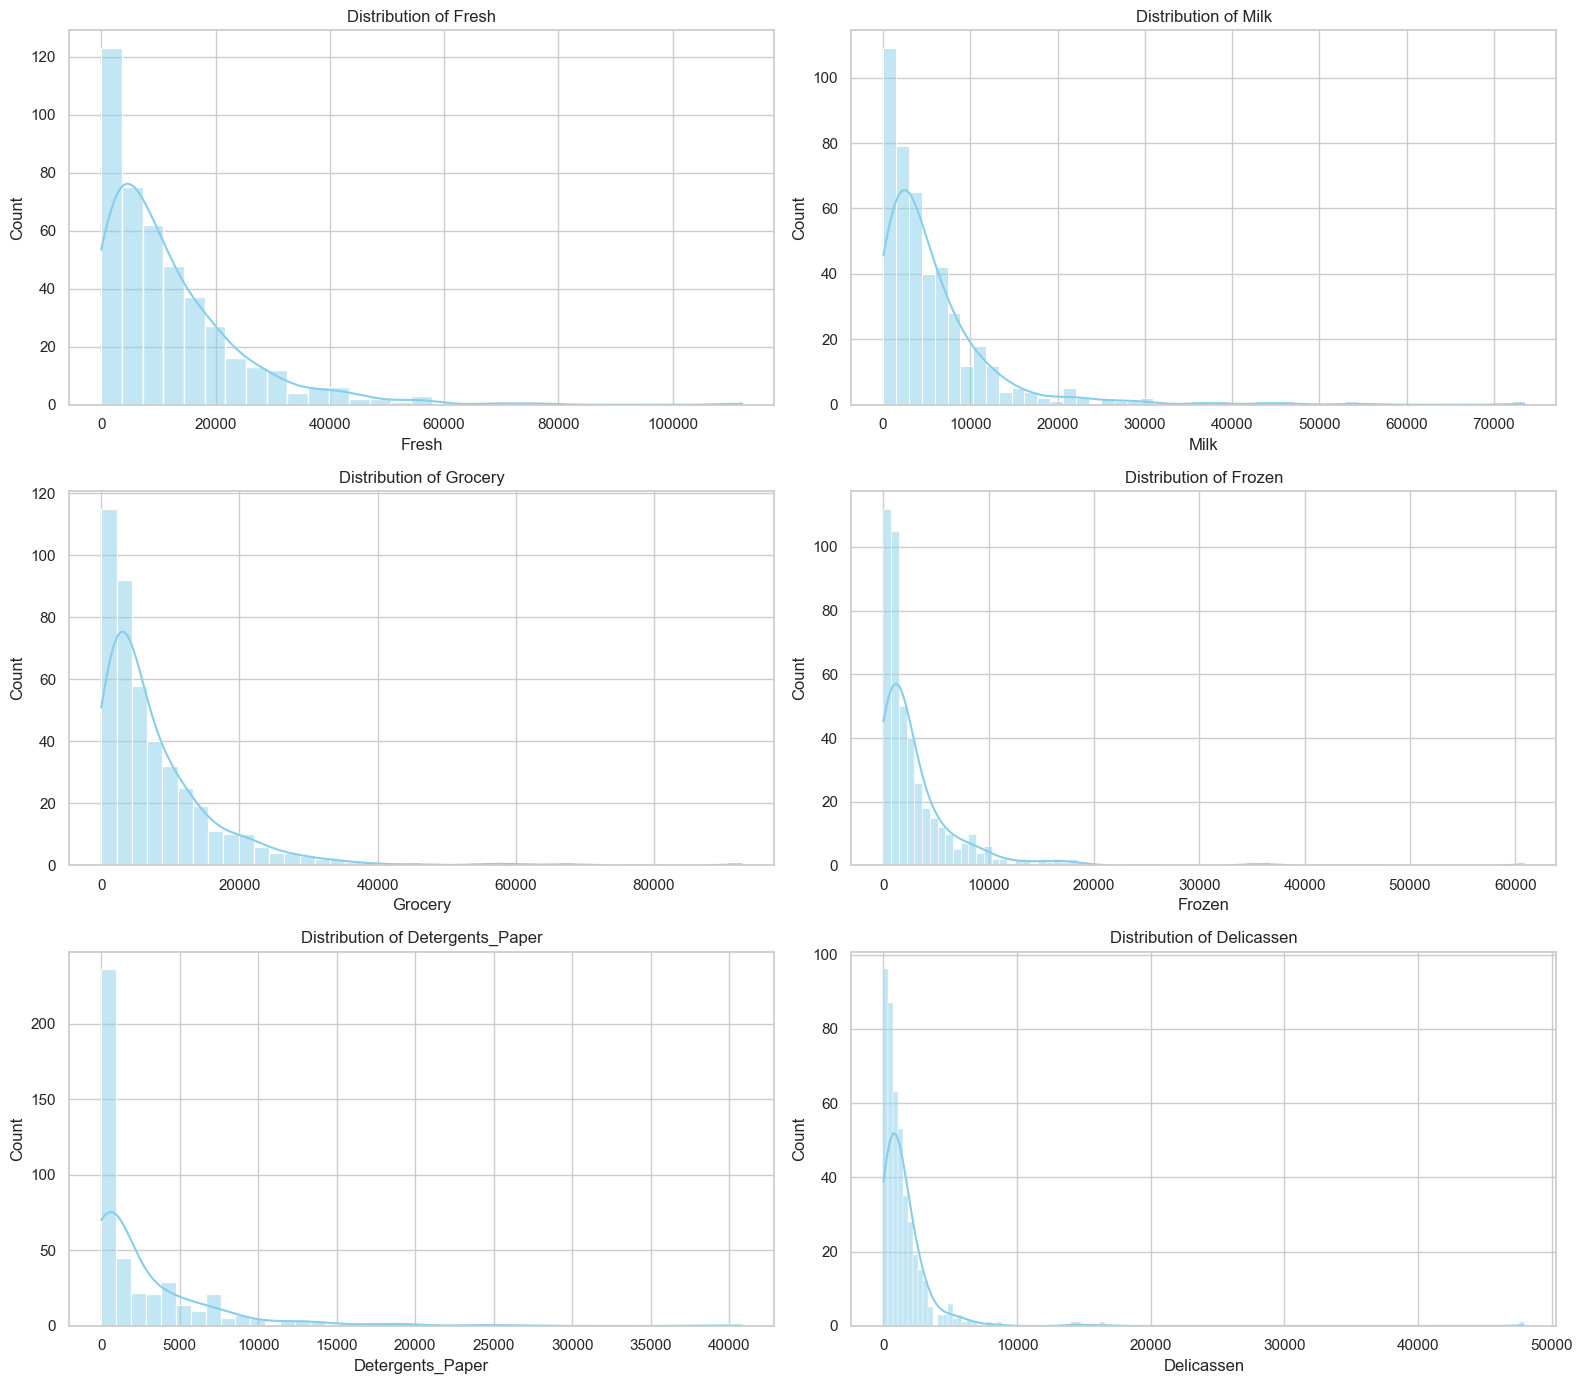

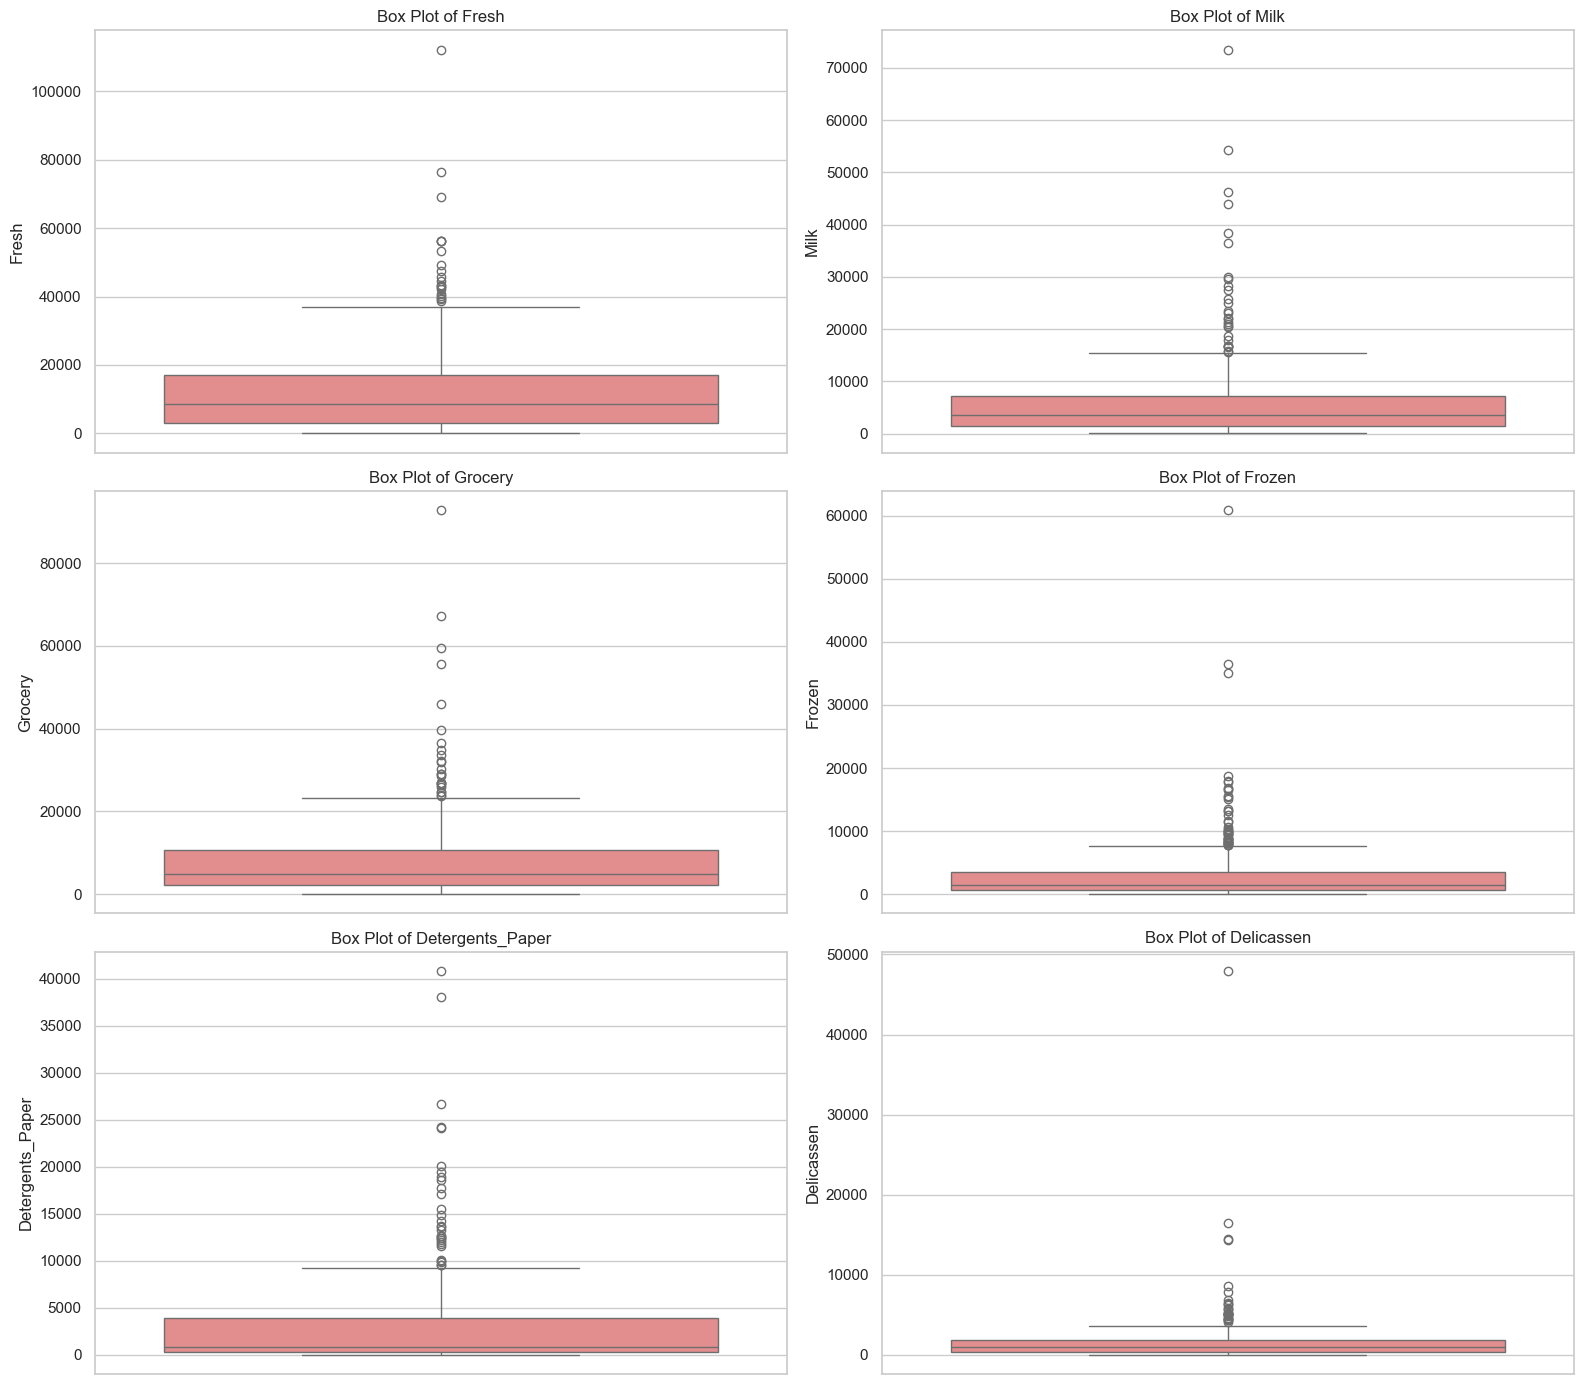

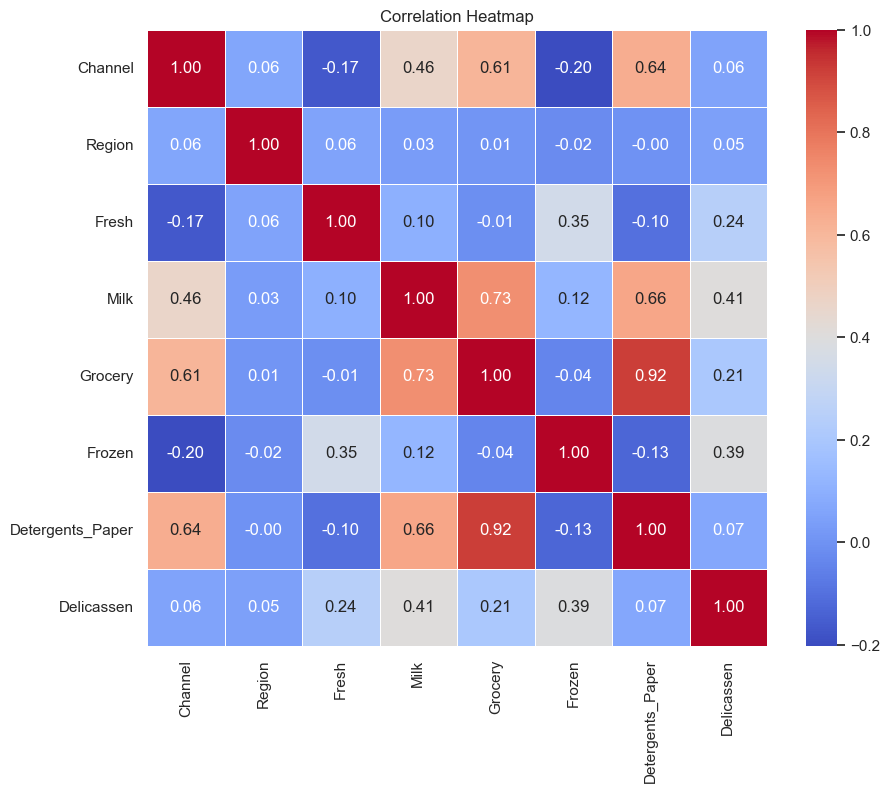

--- Outliers Detection (IQR Method) ---
Fresh: Found 20 outliers (outside range [-17581.2, 37642.8])
Milk: Found 28 outliers (outside range [-6952.9, 15676.1])
Grocery: Found 24 outliers (outside range [-10601.1, 23409.9])
Frozen: Found 43 outliers (outside range [-3475.8, 7772.2])
Detergents_Paper: Found 30 outliers (outside range [-5241.1, 9419.9])
Delicassen: Found 27 outliers (outside range [-1709.8, 3938.2])


In [11]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Set plotting style
sns.set_theme(style='whitegrid')
fig, axes = plt.subplots(3, 2, figsize=(16, 18))

# 1. Count Plots for Categorical Variables
plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
sns.countplot(data=df, x='Channel', palette='Set2')
plt.title('Distribution of Channel')

plt.subplot(1, 2, 2)
sns.countplot(data=df, x='Region', palette='Set2')
plt.title('Distribution of Region')
plt.tight_layout()
plt.show()

# 2. Histograms for Continuous Features
fig, axes = plt.subplots(3, 2, figsize=(16, 14))
axes = axes.flatten()
for i, col in enumerate(features):
    sns.histplot(df[col], kde=True, ax=axes[i], color='skyblue')
    axes[i].set_title(f'Distribution of {col}')
plt.tight_layout()
plt.show()

# 3. Box Plots to Identify Outliers
fig, axes = plt.subplots(3, 2, figsize=(16, 14))
axes = axes.flatten()
for i, col in enumerate(features):
    sns.boxplot(y=df[col], ax=axes[i], color='lightcoral')
    axes[i].set_title(f'Box Plot of {col}')
plt.tight_layout()
plt.show()

# 4. Correlation Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap')
plt.show()

# 5. Outlier Detection using IQR Method
print("--- Outliers Detection (IQR Method) ---")
for col in features:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    print(f"{col}: Found {len(outliers)} outliers (outside range [{lower_bound:.1f}, {upper_bound:.1f}])")

In [12]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Convert the scaled features back to a DataFrame for easier inspection
X_scaled_df = pd.DataFrame(X_scaled, columns=features)
X_scaled_df.head()

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,0.052933,0.523568,-0.041115,-0.589367,-0.043569,-0.066339
1,-0.391302,0.544458,0.170318,-0.270136,0.086407,0.089151
2,-0.447029,0.408538,-0.028157,-0.137536,0.133232,2.243293
3,0.100111,-0.624020,-0.392977,0.687144,-0.498588,0.093411
4,0.840239,-0.052396,-0.079356,0.173859,-0.231918,1.299347


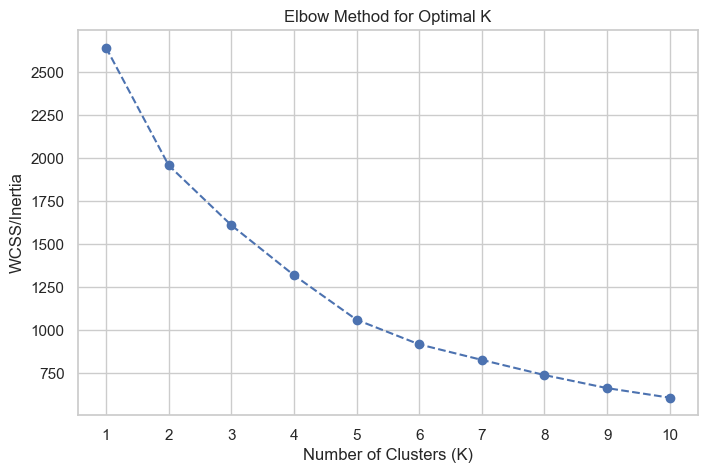

In [13]:
wcss = []
k_values = range(1, 11)

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        init='k-means++',
        random_state=42,
        n_init=10
    )
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

# Plotting after the loop completes
plt.figure(figsize=(8, 5))
plt.plot(list(k_values), wcss, marker='o', linestyle='--')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS/Inertia')
plt.xticks(list(k_values))
plt.title('Elbow Method for Optimal K')
plt.show()

In [14]:
silhouette_values = []
k_values = list(range(2, 11))

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    silhouette_values.append(score)

# Create a DataFrame to display the silhouette table nicely
silhouette_df = pd.DataFrame({
    'Number of Clusters (K)': k_values,
    'Silhouette Score': silhouette_values
})

# Display the table
print("--- Silhouette Scores Table ---")
display(silhouette_df.style.hide(axis='index').background_gradient(cmap='Blues', subset=['Silhouette Score']))



--- Silhouette Scores Table ---


Number of Clusters (K),Silhouette Score
2,0.547215
3,0.548287
4,0.348471
5,0.369040
6,0.378229
7,0.334282
8,0.320116
9,0.309028
10,0.311214


In [15]:
suggested_k = int(
    silhouette_df.loc[silhouette_df['Silhouette Score'].idxmax(), 'Number of Clusters (K)']
)

print(f"The suggested number of clusters based on the maximum Silhouette Score is: {suggested_k}")

The suggested number of clusters based on the maximum Silhouette Score is: 3


In [16]:
K = suggested_k
kmeans_model = KMeans(n_clusters=K, random_state=42, n_init=10)
kmeans_labels = kmeans_model.fit_predict(X_scaled)


In [17]:
df_kmeans = df.copy()
df_kmeans["Kmeans_Cluster"] = kmeans_labels

print("K-means clustering Completed:")
print("\nNumber of customers in each cluster")
print(df_kmeans["Kmeans_Cluster"].value_counts().sort_index())

print("\nSample records from each cluster")
display(df_kmeans.head())

K-means clustering Completed:

Number of customers in each cluster
Kmeans_Cluster
0     45
1    393
2      2
Name: count, dtype: int64

Sample records from each cluster


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,Kmeans_Cluster
0,2,3,12669,9656,7561,214,2674,1338,1
1,2,3,7057,9810,9568,1762,3293,1776,1
2,2,3,6353,8808,7684,2405,3516,7844,1
3,1,3,13265,1196,4221,6404,507,1788,1
4,2,3,22615,5410,7198,3915,1777,5185,1


In [18]:
hierarchical_model = AgglomerativeClustering(
    n_clusters=K,
    metric='euclidean',
    linkage='ward'
)
hierarchical_labels = hierarchical_model.fit_predict(X_scaled)

In [19]:
df_hierarchical = df.copy()
df_hierarchical["Hierarchical_Cluster"] = hierarchical_labels
print("Hierarchical clustering Completed:")
print("\nNumber of customers in each cluster")
print(df_hierarchical["Hierarchical_Cluster"].value_counts().sort_index())
print("\nSample records from each cluster")
display(df_hierarchical.head())

Hierarchical clustering Completed:

Number of customers in each cluster
Hierarchical_Cluster
0      6
1    281
2    153
Name: count, dtype: int64

Sample records from each cluster


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,Hierarchical_Cluster
0,2,3,12669,9656,7561,214,2674,1338,2
1,2,3,7057,9810,9568,1762,3293,1776,2
2,2,3,6353,8808,7684,2405,3516,7844,2
3,1,3,13265,1196,4221,6404,507,1788,1
4,2,3,22615,5410,7198,3915,1777,5185,1


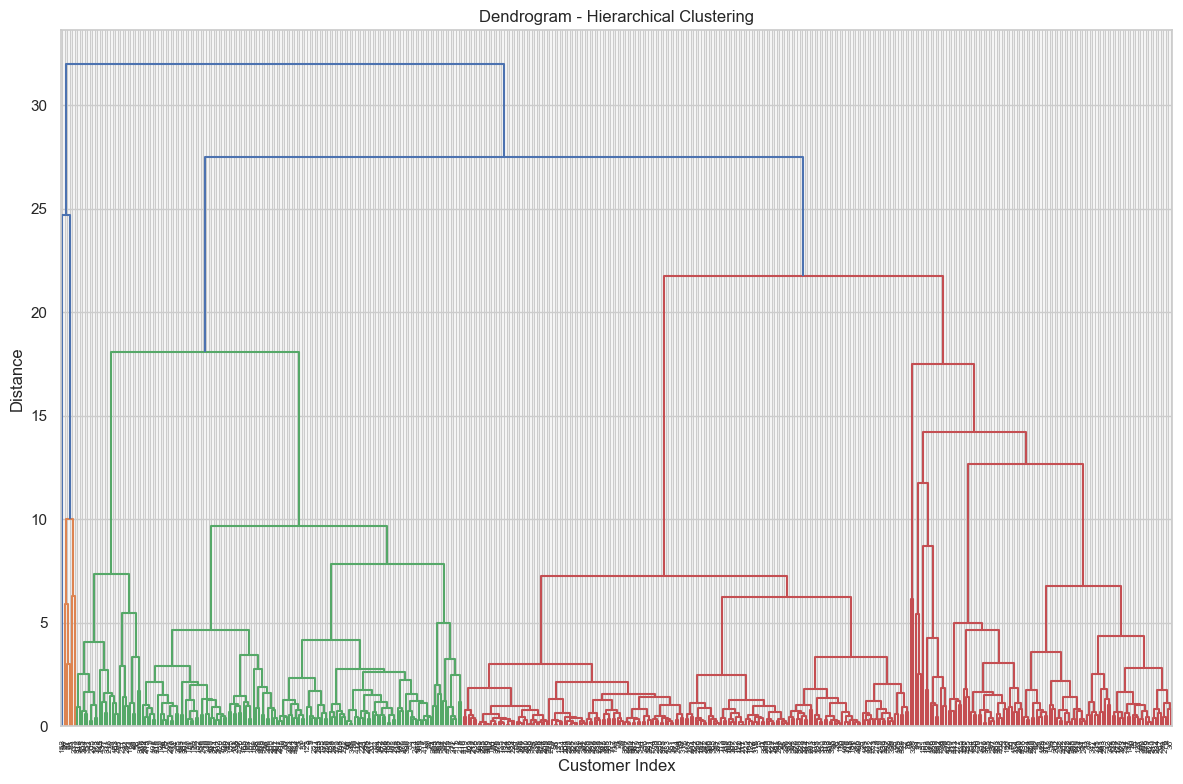

In [20]:
Z = linkage(X_scaled, method='ward', metric='euclidean')

plt.figure(figsize=(12, 8))
dendrogram(Z, truncate_mode='level', leaf_rotation=90, leaf_font_size=6, show_contracted=True)

plt.title("Dendrogram - Hierarchical Clustering")
plt.xlabel("Customer Index")
plt.ylabel("Distance")
plt.tight_layout()
plt.show()

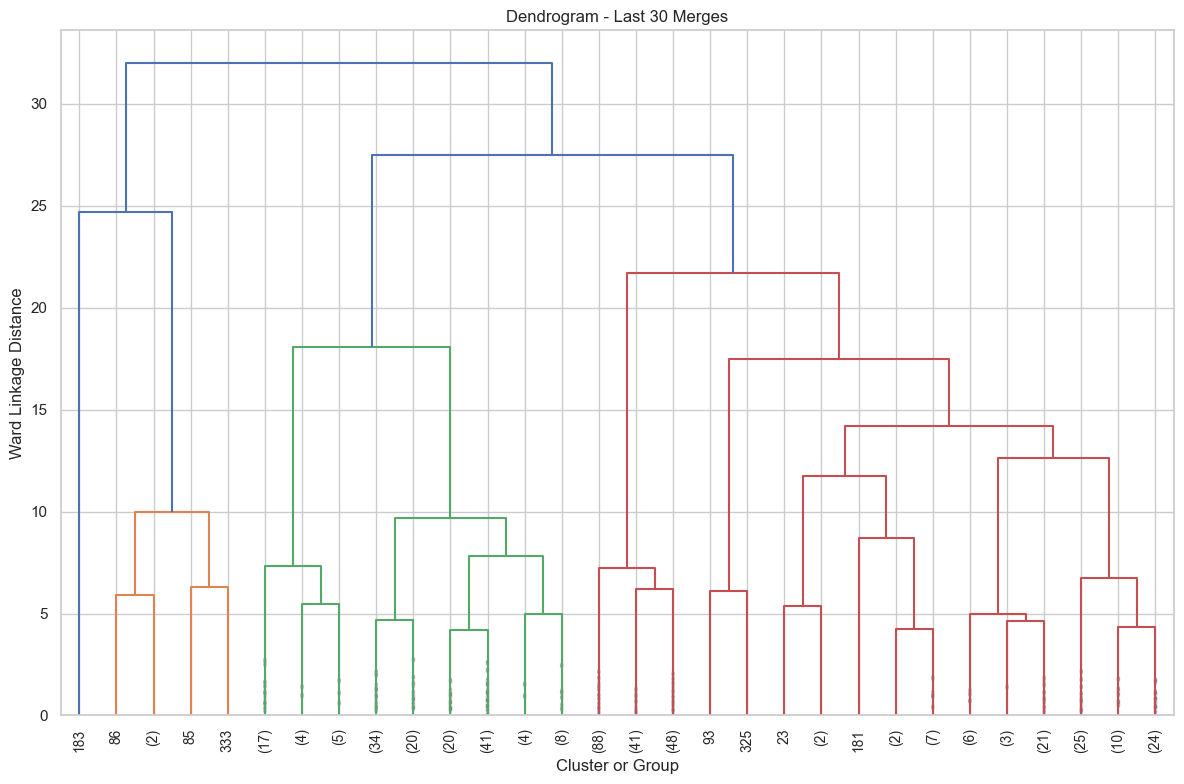

In [21]:
plt.Figure(figsize=(12, 8))
dendrogram(Z, truncate_mode='lastp', p=30, leaf_rotation=90, leaf_font_size=10, show_contracted=True)
plt.title("Dendrogram - Last 30 Merges")
plt.xlabel("Cluster or Group")
plt.ylabel("Ward Linkage Distance")
plt.tight_layout()
plt.show()

In [22]:
pca=PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print("Explained variance ratio by each principal component:",
      round(pca.explained_variance_ratio_.sum()*100,2 ))

plot_df=pd.DataFrame({"PC1": X_pca[:, 0], "PC2": X_pca[:, 1],
                       "Kmeans_Cluster": kmeans_labels,
                         "Hierarchical_Cluster": hierarchical_labels})

Explained variance ratio by each principal component: 72.46


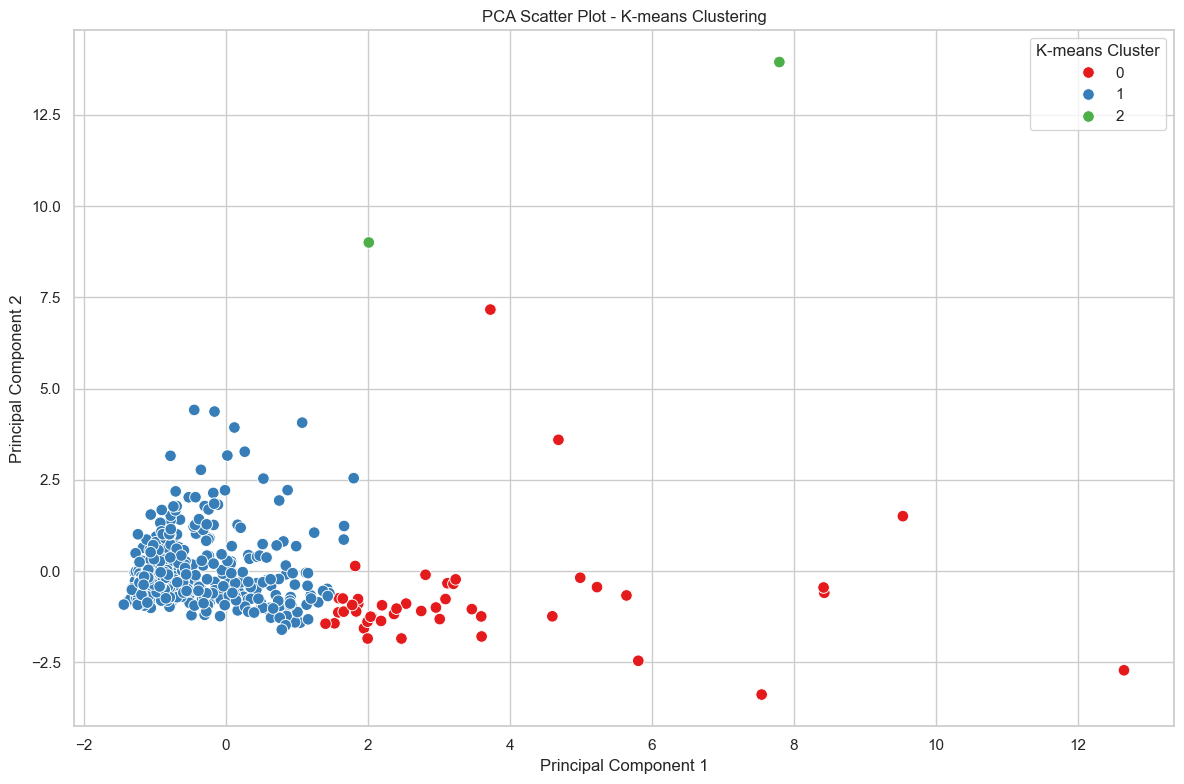

In [23]:
plt.Figure(figsize=(12, 8))
sns.scatterplot(data=plot_df, x="PC1", y="PC2", hue="Kmeans_Cluster", palette='Set1', s=70)
plt.title("PCA Scatter Plot - K-means Clustering")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title='K-means Cluster')
plt.tight_layout()
plt.show()

In [24]:
def evaluate_clustering(X_scaled, labels, method_name):
    return {
        "Method": method_name,
        "Silhouette Score": silhouette_score(X_scaled, labels),
        "Davies-Bouldin Index": davies_bouldin_score(X_scaled, labels),
        "Calinski-Harabasz Index": calinski_harabasz_score(X_scaled, labels)}

In [25]:
cluster_sizes = pd.DataFrame({
    "K-means Cluster": df_kmeans["Kmeans_Cluster"].value_counts().sort_index(),
    "Hierarchical Cluster": df_hierarchical["Hierarchical_Cluster"].value_counts().sort_index()}).fillna(0).astype(int)
print("Cluster Sizes Comparison:")
display(cluster_sizes.style.hide(axis='index').background_gradient(cmap='coolwarm'))

Cluster Sizes Comparison:


K-means Cluster,Hierarchical Cluster
45,6
393,281
2,153


In [26]:
kmeans_profile = df[features].copy()
kmeans_profile["Cluster"] = kmeans_labels
kmeans_means = kmeans_profile.groupby("Cluster")[features].mean()
display(kmeans_means)


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Cluster,,,,,,
0,10440.933333,19386.422222,28656.088889,2190.244444,13327.800000,2374.200000
1,12062.913486,4115.099237,5534.966921,2940.676845,1696.170483,1299.114504
2,34782.000000,30367.000000,16898.000000,48701.500000,755.500000,26776.000000


In [27]:
cluster_distribution = pd.DataFrame({
    "Customer Count":pd.Series(kmeans_labels).value_counts().sort_index()
})
cluster_distribution["Percentage"]=(
    cluster_distribution["Customer Count"]/cluster_distribution["Customer Count"].sum()*100
)

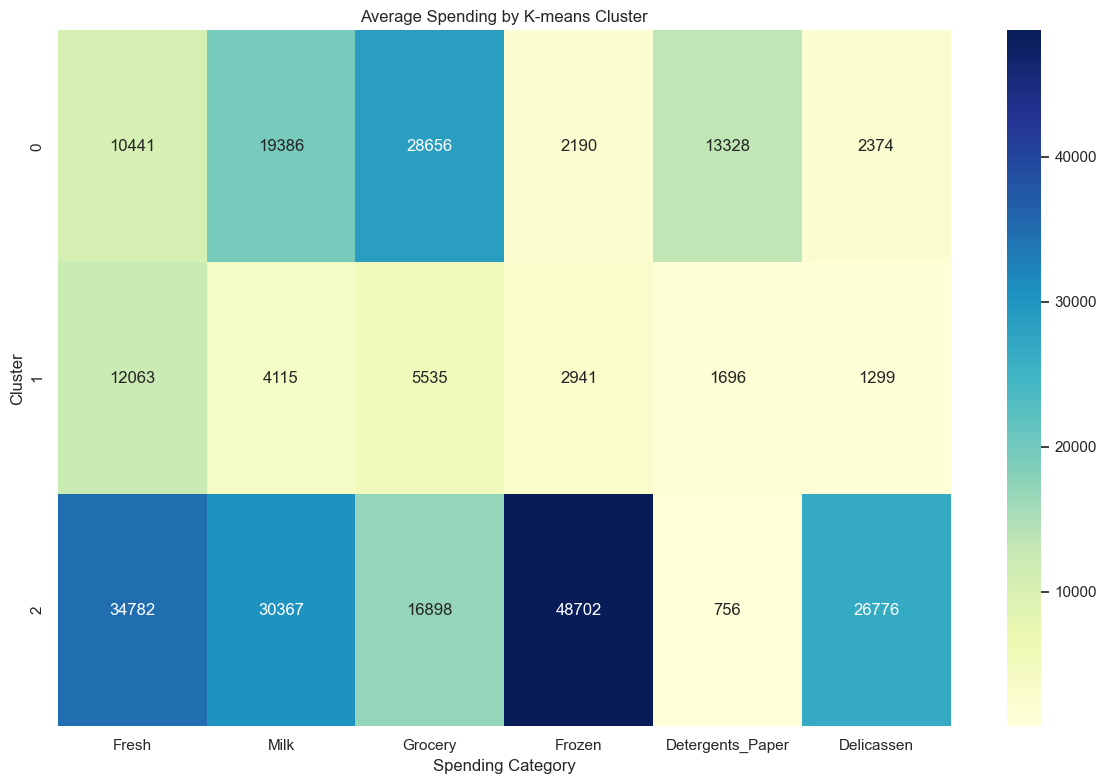

In [28]:
plt.Figure(figsize=(12,6))
sns.heatmap(kmeans_means,annot=True,fmt=".0f",cmap="YlGnBu")
plt.title("Average Spending by K-means Cluster")
plt.xlabel("Spending Category")
plt.ylabel("Cluster")
plt.tight_layout()
plt.show()

In [29]:
channel_mix = pd.crosstab(df["Channel"],kmeans_labels,normalize="columns")*100
channel_mix.columns = [f"Cluster {c}" for c in channel_mix.columns]
print("Channel compostion within each K-Means Cluster (%):")
display(channel_mix.round(2))

Channel compostion within each K-Means Cluster (%):


,Cluster 0,Cluster 1,Cluster 2
Channel,,,
1,2.22,75.06,100.0
2,97.78,24.94,0.0
